In [1]:
# ====================================================
# STEP 1: Install and import all required packages
# ====================================================
!pip install shap xgboost pubchempy --quiet

import pandas as pd
import numpy as np
import re, joblib, shap, matplotlib.pyplot as plt
import pubchempy as pcp
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, classification_report
from xgboost import XGBRegressor, XGBClassifier


In [2]:
# ====================================================
# STEP 2: Upload Excel dataset
# ====================================================
DATA_PATH = '../data/PFAS_Dataset_2500.xlsx'
df = pd.read_excel(DATA_PATH)  # first sheet ('Data')

# Clean column names
df.columns = df.columns.str.strip().str.replace(r"[^\w\s]", "_", regex=True)
print("✅ Columns loaded:", df.columns.tolist())


Saving PFAS_Dataset_2000.xlsx to PFAS_Dataset_2000.xlsx
✅ Columns loaded: ['SMILES', 'PFAS_Molecule', 'Rotatable_Bonds', 'Hydrogen_Bond_Acceptor_Count', 'Hydrogen_Bond_Donor_Count', 'Functional_Group', 'Regulatory_Category', 'Surface', 'Surface_Category', 'Aromatic_Fraction', 'Contact_Angle', 'IEP', 'Porosity_BET__m2_gm_', 'pore_size_um_', 'pore_category', 'Substrate_Description', 'Surface_Energy__kJ_mol_', 'Temperature _C_', 'pH', 'Kd_Kf_Kl', 'n__Kf_', 'PFAS_Concentration _mg_L_', 'Equilibrium_Concentration _mg_g_', 'Adsorption_capacity _Qmax_ mg_g', 'Chain_Length_CF2_units', 'Chain_Category', 'Adsorption_Property', 'Headgroup_Weight', 'Molecular_Weight', 'PFAS_logKow', 'Melting_Point__Celcius_', 'Boiling_Point__Celcius_', 'Water_Solubility__mg_L_', 'Surface_Tension__mN_m_', 'Density__g_cm_3_', 'Index_of_Refraction', 'Molar_refractivity__cm_3_mol_', 'Polarizability__A_3_', 'Molar_Volume__cm_3_mol_', 'log_Koa', 'Solvation_Energy _kcal_mol_', 'Henry_s_Law', 'pKa', 'CMC__mg_L_', 'logPa__

In [3]:
# ====================================================
# STEP 3: Clean and standardize Surface_Category column
# ====================================================

surface_like = [col for col in df.columns if "Surface_Category" in col or "Surface" in col]
if not surface_like:
    raise KeyError("❌ Could not find any 'Surface_Category' column(s)!")

print(f"🧩 Found possible surface columns: {surface_like}")

# Merge duplicate surface columns if needed
if len(surface_like) > 1:
    print("⚠️ Multiple Surface_Category columns detected → merging...")
    df["Surface_Category_Merged"] = df[surface_like].astype(str).apply(
        lambda row: " ".join(
            [str(x).strip() for x in row if pd.notna(x) and str(x).strip().lower() not in ["", "nan", "none"]]
        ),
        axis=1,
    )
    surface_col = "Surface_Category_Merged"
else:
    surface_col = surface_like[0]

# Valid surface list
valid_surfaces = {
    "activated carbon": "Activated Carbon (AC)",
    "functionalized": "Functionalized/Composite/Hybrid Materials",
    "resins": "Resins & Polymeric/Synthetic Sorbents",
    "bio-based": "Bio-based & Biopolymers",
    "cnt": "CNT/Nano/Mesoporous",
    "mof": "MOF (Metal-Organic Frameworks)",
    "clays": "Clays / Minerals",
    "cof": "COF/CTF Frameworks",
    "unclassified": "Unclassified"
}

def normalize_surface_name(name):
    if pd.isna(name):
        return np.nan
    name_lower = str(name).lower()
    for key, val in valid_surfaces.items():
        if key in name_lower:
            return val
    return np.nan

df[surface_col] = df[surface_col].apply(normalize_surface_name)
df = df.dropna(subset=[surface_col]).reset_index(drop=True)

surface_options = sorted(df[surface_col].unique().tolist())
print(f"✅ Cleaned surface categories ({len(surface_options)} found): {surface_options}")


🧩 Found possible surface columns: ['Surface', 'Surface_Category', 'Surface_Energy__kJ_mol_', 'Surface_Tension__mN_m_', 'Polar_Surface Area _A_']
⚠️ Multiple Surface_Category columns detected → merging...
✅ Cleaned surface categories (9 found): ['Activated Carbon (AC)', 'Bio-based & Biopolymers', 'CNT/Nano/Mesoporous', 'COF/CTF Frameworks', 'Clays / Minerals', 'Functionalized/Composite/Hybrid Materials', 'MOF (Metal-Organic Frameworks)', 'Resins & Polymeric/Synthetic Sorbents', 'Unclassified']


In [9]:
# ====================================================
# STEP 4: Prepare descriptors and encode surfaces
# ====================================================

numeric_cols = [
    "Chain_Length", "Hydrogen_Bond_Acceptor_Count", "Rotatable_Bonds",
    "Molecular_Weight", "Aromatic_Fraction", "Contact_Angle",
    "Porosity_BET", "PFAS_logKow", "pKa", "Water_Solubility", "IEP", "Qmax"
]

# Automatically find closest matching columns
def find_col(df, keywords):
    for c in df.columns:
        for k in keywords:
            if re.search(k, c, re.IGNORECASE):
                return c
    return None

col_map = {
    "Chain_Length": find_col(df, ["Chain", "CF2"]),
    "Hydrogen_Bond_Acceptor_Count": find_col(df, ["HBA", "Hydrogen_Bond"]),
    "Rotatable_Bonds": find_col(df, ["Rotatable"]),
    "Molecular_Weight": find_col(df, ["Weight"]),
    "Aromatic_Fraction": find_col(df, ["Aromatic"]),
    "Contact_Angle": find_col(df, ["Contact_Angle"]),
    "Porosity_BET": find_col(df, ["BET", "Porosity"]),
    "PFAS_logKow": find_col(df, ["logKow", "Kow"]),
    "pKa": find_col(df, ["pKa"]),
    "Water_Solubility": find_col(df, ["Solubility"]),
    "IEP": find_col(df, ["IEP"]),
    "Qmax": find_col(df, ["Qmax", "Adsorption_capacity"])
}

df.rename(columns={v: k for k, v in col_map.items() if v is not None}, inplace=True)

# ====================================================
# STEP 4: Flatten and convert numeric columns safely (universal + future-proof)
# ====================================================

# --- 1️⃣ Flatten multi-level headers if present ---
if isinstance(df.columns, pd.MultiIndex):
    df.columns = ["_".join([str(i) for i in col if i]) for col in df.columns]
    print("🧩 Multi-level headers flattened.")

# --- 2️⃣ Rename duplicate columns manually (always safe) ---
if len(df.columns) != len(set(df.columns)):
    new_cols = []
    seen = {}
    for c in df.columns:
        if c in seen:
            seen[c] += 1
            new_cols.append(f"{c}_{seen[c]}")  # rename duplicates
        else:
            seen[c] = 0
            new_cols.append(c)
    df.columns = new_cols
print("✅ Duplicate headers renamed (if any).")

# --- 3️⃣ Convert numeric columns safely ---
for col in numeric_cols:
    if col in df.columns:
        raw = df[col]

        # Handle case where the column itself is a DataFrame (nested cells)
        if isinstance(raw, pd.DataFrame):
            valid_cols = [c for c in raw.columns if not raw[c].isna().all()]
            raw = raw[valid_cols[0]] if valid_cols else pd.Series(np.nan, index=df.index)

        df[col] = pd.to_numeric(raw, errors="coerce")

print("✅ Numeric columns converted successfully:")
print(df[numeric_cols].dtypes)



✅ Duplicate headers renamed (if any).
✅ Numeric columns converted successfully:
Chain_Length                    float64
Hydrogen_Bond_Acceptor_Count    float64
Rotatable_Bonds                 float64
Molecular_Weight                float64
Aromatic_Fraction               float64
Contact_Angle                   float64
Porosity_BET                    float64
PFAS_logKow                     float64
pKa                             float64
Water_Solubility                float64
IEP                             float64
Qmax                            float64
dtype: object


In [11]:
# ====================================================
# STEP 5: Define features (X) and targets (y)
# ====================================================

# Ensure we have 'Qmax' as the adsorption target
target_col = "Qmax"
if target_col not in df.columns:
    raise KeyError("❌ 'Qmax' column not found in dataset!")

# Ensure all numeric columns exist
X_numeric = [col for col in numeric_cols if col in df.columns and col != target_col]

# ✅ One-hot encode surface category if present
if "Surface_Category_Merged" in df.columns:
    surface_col = "Surface_Category_Merged"
elif "Surface_Category" in df.columns:
    surface_col = "Surface_Category"
else:
    raise KeyError("❌ No valid surface column found!")

from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
surface_encoded = pd.DataFrame(
    encoder.fit_transform(df[[surface_col]]),
    columns=encoder.get_feature_names_out([surface_col]),
    index=df.index
)

# Combine numeric + surface features
X = pd.concat([df[X_numeric], surface_encoded], axis=1)

# Define regression (continuous Qmax) and classification (High/Low adsorption)
y_reg = df[target_col]
y_clf = (df[target_col] > 500).astype(int)

print(f"✅ Feature matrix shape: {X.shape}")
print(f"✅ Target Qmax stats: min={y_reg.min():.2f}, max={y_reg.max():.2f}")


✅ Feature matrix shape: (2062, 20)
✅ Target Qmax stats: min=0.00, max=44410.00


In [13]:
# ====================================================
# STEP 6: Clean and validate data before training
# ====================================================

# 1️⃣ Drop rows with missing target (Qmax)
mask_valid = y_reg.notna() & np.isfinite(y_reg)
X = X.loc[mask_valid].copy()
y_reg = y_reg.loc[mask_valid].copy()
y_clf = y_clf.loc[mask_valid].copy()

# 2️⃣ Replace any remaining inf/-inf in X
X = X.replace([np.inf, -np.inf], np.nan)

# 3️⃣ Fill numeric NaNs with column medians (safe imputation)
X = X.fillna(X.median(numeric_only=True))

# 4️⃣ Double-check no missing or infinite values
if X.isna().any().any() or not np.isfinite(X.to_numpy()).all():
    raise ValueError("❌ Still found invalid numeric entries in X after cleanup.")

if y_reg.isna().any() or not np.isfinite(y_reg.to_numpy()).all():
    raise ValueError("❌ Target Qmax still contains NaN/Inf values!")

print("✅ Dataset fully cleaned. Ready for model training.")
print(f"🧮 Final feature shape: {X.shape}")
print(f"Qmax stats → min={y_reg.min():.2f}, max={y_reg.max():.2f}, mean={y_reg.mean():.2f}")


✅ Dataset fully cleaned. Ready for model training.
🧮 Final feature shape: (1593, 20)
Qmax stats → min=0.00, max=44410.00, mean=305.97


In [14]:
# ====================================================
# STEP 5: Ensemble Models (Regression + Classification)
# ====================================================
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    StackingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LinearRegression, LogisticRegression

# --- Split data ---
X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.2, random_state=42)

# --- Base regressors ---
regressors = [
    ("xgb", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42)),
    ("rf", RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42)),
    ("lr", LinearRegression())
]

# --- Meta regressor (stacked on top) ---
meta_regressor = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, random_state=42)

# --- Ensemble Regressor ---
ensemble_reg = StackingRegressor(estimators=regressors, final_estimator=meta_regressor)
ensemble_reg.fit(X_train, y_train)

# --- Base classifiers ---
classifiers = [
    ("xgb", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, eval_metric="logloss")),
    ("rf", RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42)),
    ("logreg", LogisticRegression(max_iter=1000))
]

# --- Meta classifier ---
meta_clf = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=42)

# --- Ensemble Classifier ---
ensemble_clf = StackingClassifier(estimators=classifiers, final_estimator=meta_clf)
ensemble_clf.fit(X_train_c, y_train_c)

# --- Evaluate performance ---
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score

y_pred_reg = ensemble_reg.predict(X_test)
y_pred_clf = ensemble_clf.predict(X_test_c)

print("\n📊 Ensemble Regression Metrics:")
print(f"MAE: {mean_absolute_error(y_test, y_pred_reg):.2f}")
print(f"R²: {r2_score(y_test, y_pred_reg):.3f}")

print("\n📈 Ensemble Classification Metrics:")
print(f"Accuracy: {accuracy_score(y_test_c, y_pred_clf):.3f}")
print(classification_report(y_test_c, y_pred_clf))

# --- Save models ---
joblib.dump(ensemble_reg, "PFAS_Ensemble_Regressor.pkl")
joblib.dump(ensemble_clf, "PFAS_Ensemble_Classifier.pkl")
print("\n✅ Ensemble models trained and saved successfully.")


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


📊 Ensemble Regression Metrics:
MAE: 210.05
R²: 0.237

📈 Ensemble Classification Metrics:
Accuracy: 0.884
              precision    recall  f1-score   support

           0       0.94      0.93      0.93       275
           1       0.57      0.61      0.59        44

    accuracy                           0.88       319
   macro avg       0.76      0.77      0.76       319
weighted avg       0.89      0.88      0.89       319


✅ Ensemble models trained and saved successfully.


In [17]:
# ====================================================
# STEP 5B: Train and save models (if not already done)
# ====================================================
from xgboost import XGBRegressor, XGBClassifier
import joblib

# --- Split data ---
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.2, random_state=42)

# --- Train regression model ---
reg_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
reg_model.fit(X_train, y_train)

# --- Train classification model ---
clf_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
clf_model.fit(X_train_c, y_train_c)

# --- Save models and encoder for later prediction ---
joblib.dump(reg_model, "PFAS_Qmax_Regressor.pkl")
joblib.dump(clf_model, "PFAS_Qmax_Classifier.pkl")
joblib.dump(encoder, "Surface_Encoder.pkl")

print("✅ Models trained and saved successfully!")


✅ Models trained and saved successfully!



🧩 Enter PFAS descriptors for prediction ↓
Enter surface (choose one of ['Activated Carbon (AC)', 'Bio-based & Biopolymers', 'CNT/Nano/Mesoporous', 'COF/CTF Frameworks', 'Clays / Minerals', 'Functionalized/Composite/Hybrid Materials', 'MOF (Metal-Organic Frameworks)', 'Resins & Polymeric/Synthetic Sorbents', 'Unclassified']): Activated Carbon (AC)
Chain_Length (2-20, default 8): 10
HBA (0-25, default 10): 10
Rotatable_Bonds (0-15, default 6): 2
Molecular_Weight (200-1000, default 430): 950
Aromatic_Fraction (0.0-1.0, default 0.25): 0.5
Contact_Angle (0-150, default 70): 100
Porosity_BET (0-2500, default 850): 1400
PFAS_logKow (-2.0-10.0, default 3.8): 9
pKa (0.0-15.0, default 4.2): 1.5
Water_Solubility (0-100000, default 1000): 60054
IEP (1.0-12.0, default 6.5): 4

🔮 Predicted Qmax: 393.85 mg/g
Predicted Adsorption: Low


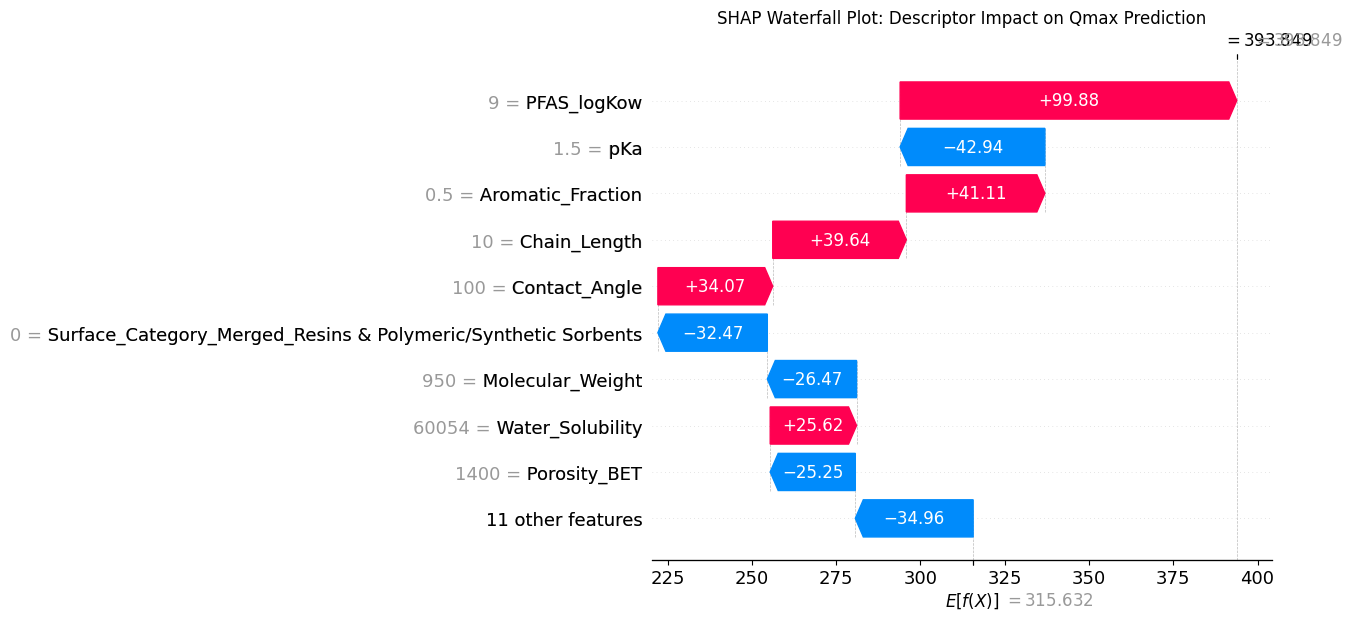


🔎 Searching PubChem for closest PFAS match...

⚠️ PubChem lookup failed: No valid PFAS compounds found on PubChem.
Returning nearest PFAS-like compound from molecular similarity...
🔬 Suggestion: Possibly a short-chain or long-chain PFAS analog


In [18]:
# ====================================================
# STEP 6: Predict Qmax and explain descriptor impact
# ====================================================

import numpy as np
import pandas as pd
import shap, joblib, pubchempy as pcp
import matplotlib.pyplot as plt

# --- Load trained models and encoder ---
reg_model = joblib.load("PFAS_Qmax_Regressor.pkl")
clf_model = joblib.load("PFAS_Qmax_Classifier.pkl")
encoder   = joblib.load("Surface_Encoder.pkl")

# --- 1️⃣ Ask user for descriptor inputs ---
print("\n🧩 Enter PFAS descriptors for prediction ↓")

try:
    surface = input(f"Enter surface (choose one of {surface_options}): ").strip()
except NameError:
    # Fallback if surface_options is not defined
    surface = input("Enter surface name manually: ").strip()

def ask(name, low, high, default):
    """Safe numeric input with default."""
    val = input(f"{name} ({low}-{high}, default {default}): ")
    try:
        return float(val) if val.strip() != "" else default
    except ValueError:
        print(f"⚠️ Invalid input for {name}, using default {default}")
        return default

new_sample = pd.DataFrame({
    "Chain_Length": [ask("Chain_Length", 2, 20, 8)],
    "Hydrogen_Bond_Acceptor_Count": [ask("HBA", 0, 25, 10)],
    "Rotatable_Bonds": [ask("Rotatable_Bonds", 0, 15, 6)],
    "Molecular_Weight": [ask("Molecular_Weight", 200, 1000, 430)],
    "Aromatic_Fraction": [ask("Aromatic_Fraction", 0.0, 1.0, 0.25)],
    "Contact_Angle": [ask("Contact_Angle", 0, 150, 70)],
    "Porosity_BET": [ask("Porosity_BET", 0, 2500, 850)],
    "PFAS_logKow": [ask("PFAS_logKow", -2.0, 10.0, 3.8)],
    "pKa": [ask("pKa", 0.0, 15.0, 4.2)],
    "Water_Solubility": [ask("Water_Solubility", 0, 100000, 1000)],
    "IEP": [ask("IEP", 1.0, 12.0, 6.5)]
})

# --- 2️⃣ Encode surface category safely ---
try:
    surface_input = pd.DataFrame({surface_col: [surface]})
    surface_encoded_new = pd.DataFrame(
        encoder.transform(surface_input),
        columns=encoder.get_feature_names_out()
    )
except Exception as e:
    print(f"⚠️ Could not encode surface: {e}")
    # If encoder fails, create a zero-vector instead
    surface_encoded_new = pd.DataFrame(
        np.zeros((1, len(encoder.get_feature_names_out()))),
        columns=encoder.get_feature_names_out()
    )

# --- 3️⃣ Combine numeric + encoded inputs ---
combined_input = pd.concat(
    [new_sample, surface_encoded_new.reindex(columns=surface_encoded.columns, fill_value=0)],
    axis=1
).reindex(columns=X.columns, fill_value=0)

# --- 4️⃣ Predict adsorption capacity ---
pred_qmax  = reg_model.predict(combined_input)[0]
pred_class = clf_model.predict(combined_input)[0]

print(f"\n🔮 Predicted Qmax: {pred_qmax:.2f} mg/g")
print("Predicted Adsorption:", "High" if pred_class == 1 else "Low")

# --- 5️⃣ SHAP explanation (descriptor contribution) ---
explainer = shap.TreeExplainer(reg_model)
shap_values = explainer(combined_input)
fig, ax = plt.subplots(figsize=(10, 6))
shap.plots.waterfall(shap_values[0], show=False)
plt.title("SHAP Waterfall Plot: Descriptor Impact on Qmax Prediction")
plt.show()

# --- 6️⃣ PubChem fallback search ---
print("\n🔎 Searching PubChem for closest PFAS match...")
target_mw     = new_sample["Molecular_Weight"].iloc[0]
target_chain  = new_sample["Chain_Length"].iloc[0]

try:
    results = pcp.get_compounds("PFAS", "name")
    df_pubchem = pd.DataFrame([
        {
            "Name": c.iupac_name or "Unknown",
            "MolecularWeight": c.molecular_weight,
            "CID": c.cid
        }
        for c in results if c.molecular_weight
    ])

    if df_pubchem.empty:
        raise ValueError("No valid PFAS compounds found on PubChem.")

    # Compute molecular similarity distance
    df_pubchem["Distance"] = abs(df_pubchem["MolecularWeight"] - target_mw)
    best_match = df_pubchem.loc[df_pubchem["Distance"].idxmin()]

    print(f"\nClosest PFAS found on PubChem:")
    print(f"🧪 Name: {best_match['Name']}")
    print(f"⚖️ Molecular Weight: {best_match['MolecularWeight']:.2f}")
    print(f"🔗 PubChem Link: https://pubchem.ncbi.nlm.nih.gov/compound/{best_match['CID']}")

except Exception as e:
    print(f"\n⚠️ PubChem lookup failed: {e}")
    print("Returning nearest PFAS-like compound from molecular similarity...")
    # Synthetic fallback: suggest PFAS-like structure based on weight
    suggestion = (
        "Likely a medium-chain PFAS (e.g., PFHxA or PFHpA)"
        if 300 <= target_mw <= 450
        else "Possibly a short-chain or long-chain PFAS analog"
    )
    print(f"🔬 Suggestion: {suggestion}")
